In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("D:\\Data Analyst\\Cohort_Retention_and_Customer_Lifetime_Value\\Data\\Raw\\online_retail_II.csv")

In [2]:
print(df.shape)

(1067371, 8)


In [3]:
print(df.isnull().sum())

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [4]:
clean_df = df.dropna(axis=0, how='all', subset=["Customer ID"])


In [5]:
print(clean_df.shape)

(824364, 8)


In [20]:
clean_df = clean_df[~clean_df['Invoice'].str.startswith('C', na=False)]


In [10]:
print(clean_df.shape)

(805620, 8)


In [16]:
non_positive_rows = (clean_df['Price'] <= 0).sum()
print("Non-positivr price rows:",non_positive_rows)

non_qpositive_rows = (clean_df['Quantity'] <= 0).sum()
print("Non-positivr Quantity rows:",non_qpositive_rows)


Non-positivr price rows: 71
Non-positivr Quantity rows: 0


In [26]:
clean_df = clean_df[(clean_df["Quantity"] > 0) & (clean_df["Price"] > 0)]


In [19]:
print(clean_df.shape)

(805549, 8)


In [22]:
clean_df = clean_df[~clean_df['StockCode'].str.contains('POST|M|D', na=False)]


In [23]:
print(clean_df.shape)

(795778, 8)


In [24]:
clean_df['revenue'] = clean_df['Quantity'] * clean_df['Price']


In [25]:
print(clean_df.head())

  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

           InvoiceDate  Price  Customer ID         Country  revenue  
0  2009-12-01 07:45:00   6.95      13085.0  United Kingdom     83.4  
1  2009-12-01 07:45:00   6.75      13085.0  United Kingdom     81.0  
2  2009-12-01 07:45:00   6.75      13085.0  United Kingdom     81.0  
3  2009-12-01 07:45:00   2.10      13085.0  United Kingdom    100.8  
4  2009-12-01 07:45:00   1.25      13085.0  United Kingdom     30.0  


In [ ]:
clean_df['InvoiceDate'] = pd.to_datetime(clean_df['InvoiceDate'])
clean_df['Order_month'] = clean_df['InvoiceDate'].dt.to_period("M")


In [29]:
first = clean_df.groupby("Customer ID")["Order_month"].min().rename("cohort_month")
clean_df = clean_df.join(first,on="Customer ID")

print(clean_df.head())

  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  revenue  \
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom     83.4   
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom     81.0   
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom     81.0   
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom    100.8   
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom     30.0   

  Order_month cohort_month  
0     2009-12      2009-12  
1     2009-12      2009-12  
2     2009-12      2009-12  
3     2009-12      2009-12  
4     2009-12

In [34]:
clean_df["month_index"] = (clean_df["Order_month"] - clean_df["cohort_month"]).apply(lambda x: x.n)


In [ ]:
#Retention Matrix
cohort_data = clean_df.groupby(
    ["cohort_month","month_index"]
)['Customer ID'].nunique()

cohort_data

cohort_month  month_index
2009-12       0              952
              1              333
              2              317
              3              405
              4              362
                            ... 
2011-10       1               70
              2               35
2011-11       0              191
              1               27
2011-12       0               28
Name: Customer ID, Length: 325, dtype: int64

In [37]:
cohort_table = cohort_data.unstack()

In [38]:
cohort_sizes = cohort_table.iloc[:, 0]

retention_matrix = cohort_table.divide(
    cohort_sizes, axis=0
) * 100

In [39]:
retention_matrix.round(2)

month_index,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
cohort_month,,,,,,,,,,,,,,,,,,,,,
2009-12,100.0,34.98,33.30,42.54,38.03,35.92,37.82,34.35,33.72,36.13,...,30.25,26.26,30.25,28.36,25.84,25.42,31.41,30.36,40.55,19.64
2010-01,100.0,21.47,32.07,31.52,27.17,30.98,26.90,23.37,28.53,32.61,...,15.22,24.46,20.38,19.29,20.11,25.27,19.84,25.27,5.71,NaN
2010-02,100.0,23.53,22.73,29.14,24.33,19.52,19.25,28.61,25.67,27.54,...,20.32,15.78,16.04,14.44,22.73,22.99,16.58,5.88,NaN,NaN
2010-03,100.0,19.09,23.18,24.09,23.41,20.45,25.00,30.68,27.73,10.91,...,17.05,17.50,15.68,17.73,20.45,21.36,7.95,NaN,NaN,NaN
2010-04,100.0,18.84,18.84,15.75,18.49,21.92,27.74,26.71,10.62,10.96,...,15.75,14.04,14.73,18.15,22.95,5.48,NaN,NaN,NaN,NaN
2010-05,100.0,16.34,17.51,17.51,18.29,25.29,21.40,12.45,5.84,8.56,...,12.45,14.01,16.34,15.18,4.67,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,17.60,18.73,20.60,23.22,28.46,12.73,8.99,8.24,11.24,...,12.36,13.11,20.22,4.87,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,15.59,18.28,29.57,29.03,13.98,11.29,14.52,14.52,11.29,...,17.20,23.66,8.06,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,19.63,28.83,32.52,16.56,11.66,9.82,12.88,13.50,12.88,...,19.63,7.36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


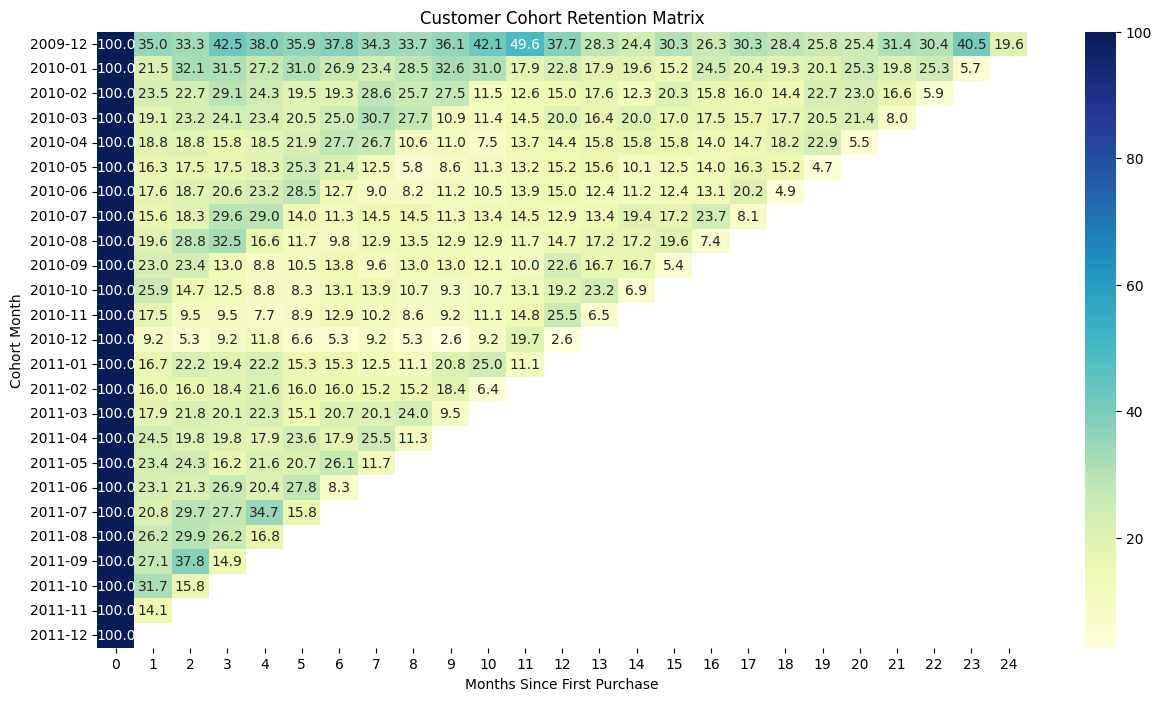

In [40]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 8))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu'
)

plt.title('Customer Cohort Retention Matrix')
plt.xlabel('Months Since First Purchase')
plt.ylabel('Cohort Month')

plt.show()